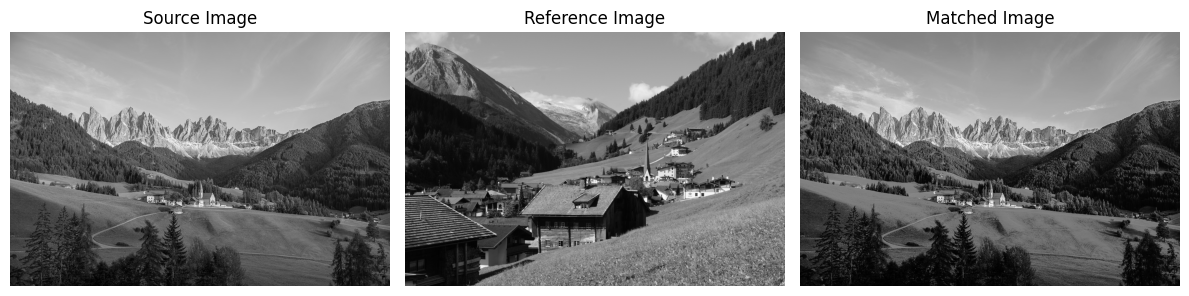

True

In [5]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Load source and reference images
source_path = "view2.jpg"
reference_path = "view3.jpg"
source_image = cv2.imread(source_path, cv2.IMREAD_GRAYSCALE)
reference_image = cv2.imread(reference_path, cv2.IMREAD_GRAYSCALE)

# Check whether images are loaded
if source_image is None:
    raise ValueError("Source image not found!")
if reference_image is None:
    raise ValueError("Reference image not found!")

# Calculate histograms
source_hist = cv2.calcHist(
    [source_image], [0], None, [256], [0, 256]
)
reference_hist = cv2.calcHist(
    [reference_image], [0], None, [256], [0, 256]
)

# Normalize histograms
source_hist /= source_hist.sum()
reference_hist /= reference_hist.sum()
# Calculate cumulative distribution functions
source_cdf = source_hist.cumsum()
reference_cdf = reference_hist.cumsum()

# Map source intensities to reference intensities
mapping = np.interp(
    source_cdf.ravel(),
    reference_cdf.ravel(),
    np.arange(256)
)
# Generate matched image
matched_image = mapping[source_image].astype(np.uint8)

# Display all three images
plt.figure(figsize=(12, 5))
plt.subplot(1, 3, 1)
plt.imshow(source_image, cmap="gray")
plt.title("Source Image")
plt.axis("off")
plt.subplot(1, 3, 2)
plt.imshow(reference_image, cmap="gray")
plt.title("Reference Image")
plt.axis("off")
plt.subplot(1, 3, 3)
plt.imshow(matched_image, cmap="gray")
plt.title("Matched Image")
plt.axis("off")
plt.tight_layout()
plt.show()

# Save matched image
cv2.imwrite("matched_image.jpg", matched_image)